# 01 · Data preparation: ingestion, cleaning and quality checks

How the corpus is built from public sources, with every step shown on the real data: provenance and licences, the raw files, the tidy
statistics table and its schema, the cleaning decisions, the data-quality checks, and how MOM web pages become chunks.
The same code runs in `make ingest` (`policy_agent.ingest.build`); this notebook calls it step by step.

| Step | Input | Output |
|---|---|---|
| Fetch | `config/corpus.json` | `data/raw/` plus `manifest.json` (hash, licence, URL, fetch time per file) |
| Structured load | 21 data.gov.sg CSVs | one tidy table, checked against a pandera schema (`stats.parquet`, `stats.duckdb`) |
| Documents | 46 MOM HTML pages, 7 synthetic memos | blocks, then structure-aware chunks of at most 400 tokens |
| Stat cards | tidy table | one short sentence per published figure, so text retrieval can find numbers |
| Quality | all of the above | `quality_report.json` |

Scope window: **2021-Q3 to 2026-Q2**; data retrieved 2026-10-27.

In [1]:
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from policy_agent.ingest.paths import CORPUS, PROCESSED, RAW, SCOPE_FROM, SCOPE_TO

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("scope window:", SCOPE_FROM, "to", SCOPE_TO)

scope window: 2021-Q3 to 2026-Q2


## 1. Provenance and licences
Every downloaded file is listed in a manifest with its source URL, licence key, SHA-256 and fetch time. The manifest is the only part of `data/raw/` that is committed.

In [2]:
manifest = pd.DataFrame(json.loads((RAW / "manifest.json").read_text()))
summary = manifest.groupby(["source", "licence"]).agg(
    files=("key", "count"), megabytes=("bytes", lambda s: round(s.sum() / 1e6, 2)), last_fetched=("fetched_at", "max")
)
display(summary)
print("Licence keys:")
for k, v in CORPUS["licences"].items():
    print(f"  {k}: {v}")

bad = [r.path for r in manifest.itertuples() if hashlib.sha256((RAW / r.path).read_bytes()).hexdigest() != r.sha256]
print(f"\nfiles whose content no longer matches the manifest hash: {len(bad)} of {len(manifest)}")

,,files,megabytes,last_fetched
source,licence,,,
datagov,sg_odl,42,0.52,2026-10-27T09:31:20+00:00
mom,mom_terms,46,2.63,2026-10-27T09:31:54+00:00


Licence keys:
  sg_odl: Singapore Open Data Licence v1.0 (https://data.gov.sg/open-data-licence)
  mom_terms: MOM website terms of use (https://www.mom.gov.sg/terms-of-use); fetched by script, not redistributed in the repo

files whose content no longer matches the manifest hash: 0 of 88


## 2. Structured data: raw to tidy
The 21 data.gov.sg datasets arrive in different shapes (wide tables, `-` for suppressed cells, quarter labels in several formats). One loader per layout turns them into a single tidy table.

In [3]:
raw = pd.read_csv(RAW / "datagov" / "job_vacancy_by_industry_q.csv", dtype=str, encoding="utf-8-sig")
print("raw file as downloaded:", raw.shape)
display(raw.iloc[:4, :6])
print("suppressed cells ('-') in this file:", int((raw == "-").sum().sum()))

raw file as downloaded: (4700, 3)


,quarter,industry,job_vacancy
0,1998-Q1,manufacturing,8200
1,1998-Q1,"food, beverages and tobacco",300
2,1998-Q1,textile and wearing apparel,600
3,1998-Q1,paper products and publishing,300


suppressed cells ('-') in this file: 23


In [4]:
from policy_agent.ingest.structured import load_structured

tidy = load_structured()
print("tidy table:", tidy.shape)
display(tidy.sample(6, random_state=0))
by_ind = tidy.groupby("indicator").agg(
    rows=("value", "size"),
    sources=("source_id", "nunique"),
    first=("period", "min"),
    last=("period", "max"),
    unit=("unit", "first"),
)
display(by_ind)

tidy table: (12418, 17)


,indicator,residency,age_group,industry,industry_level,sex,qualification,seasonal_adjustment,period,period_type,value,unit,source_id,dataset_id,release_type,release_date,in_window
10502,unemployed_persons,resident,<NA>,<NA>,<NA>,<NA>,<NA>,sa,2007-Q3,quarter,47500.0,persons,unemployed_resident_q,d_50f76f080c7e80c3b6acd4dfc9f29174,latest_revision,2026-09-29,False
8830,retrenchments,<NA>,<NA>,security and investigation,unverified,<NA>,<NA>,unspecified,2022-Q3,quarter,NaN,persons,retrenched_by_industry_q,d_61d92d31ca400be135190614277da825,latest_revision,2026-09-22,True
1523,job_vacancies,<NA>,<NA>,food and beverage services,component,<NA>,<NA>,unspecified,2025-Q2,quarter,4100.0,persons,job_vacancy_by_industry_q,d_3f17bbf67d31d4d402caa8755eb74afc,latest_revision,2026-09-22,True
2421,job_vacancies,<NA>,<NA>,manufacturing,unverified,<NA>,<NA>,unspecified,2007-Q4,quarter,8800.0,persons,job_vacancy_by_industry_q,d_3f17bbf67d31d4d402caa8755eb74afc,latest_revision,2026-09-22,False
12216,unemployment_rate,resident,<NA>,<NA>,<NA>,<NA>,<NA>,sa,2011-Q3,quarter,2.9,%,unemp_rate_resident_q,d_d1d755e060dd6b01a8024ba60b21b831,latest_revision,2026-09-29,False
1476,job_vacancies,<NA>,<NA>,food and beverage services,component,<NA>,<NA>,unspecified,2013-Q3,quarter,6100.0,persons,job_vacancy_by_industry_q,d_3f17bbf67d31d4d402caa8755eb74afc,latest_revision,2026-09-22,False


,rows,sources,first,last,unit
indicator,,,,,
job_vacancies,4842,3,1998,2026-Q2,persons
long_term_unemployed_persons,33,1,1992,2025,persons
long_term_unemployment_rate,33,1,1992,2025,%
retrenchments,4842,3,1998,2026-Q2,persons
unemployed_persons,828,3,1992-Q1,2026-Q2,persons
unemployment_rate,1698,7,1992,2026-Q2,%
vacancy_to_unemployed_ratio,142,2,1998,2026-Q2,ratio


## 3. Schema validation
The tidy table must satisfy a pandera schema: allowed indicators, residency groups and seasonal-adjustment tags, period format matching the period type, percentages not above 100, no duplicate keys, and a null value only where a suppressed industry cell is documented.

In [5]:
import pandera.pandas as pa

from policy_agent.ingest.schema import STATS_SCHEMA

STATS_SCHEMA.validate(tidy)
print("the real table passes the schema")

pct = tidy[tidy.unit == "%"].head(2).copy()
cases = {
    "a percentage of 130": pct.assign(value=[130.0, pct.value.iloc[1]]),
    "a duplicated row": pd.concat([tidy.head(1), tidy.head(1)]),
    "a quarter label with the wrong format": tidy.head(1).assign(period_type="quarter", period="2025Q9"),
}
for name, bad_frame in cases.items():
    try:
        STATS_SCHEMA.validate(bad_frame, lazy=True)
        print(f"NOT CAUGHT: {name}")
    except pa.errors.SchemaErrors as e:
        print(f"rejected: {name} -> {e.failure_cases['check'].iloc[0]}")

the real table passes the schema
rejected: a percentage of 130 -> percentage above 100
rejected: a duplicated row -> duplicate key rows
rejected: a quarter label with the wrong format -> period format must match period_type


## 4. Cleaning and transformation decisions

| Decision | Why |
|---|---|
| Quarter labels in three formats (`2026-Q2`, `2026-06`, `20262Q`) become `YYYY-Qn` | one join key across datasets |
| Seasonal adjustment is **tagged from what the dataset states**: `sa`, `nsa`, or `unspecified` | annual rates, long-term unemployment and vacancy counts do not say, and the system must not guess |
| `-` markers become missing values, and **no stat card is made for them** | a suppressed cell must lead to an abstention, not an imputed figure |
| Industry aggregates are checked against the sum of their components | catches mis-parsed or double-counted rows |
| `in_window` flags rows inside 2021-Q3 to 2026-Q2 | the evaluation and the agent use the window; earlier history stays in the store |
| Units are explicit (`%`, `persons`, `ratio`) | percentage points and percent are different quantities |

In [6]:
from policy_agent.ingest.periods import to_quarter

print({raw_label: to_quarter(raw_label) for raw_label in ["2026-Q2", "2026-06", "20262Q"]})
print()
display(tidy.seasonal_adjustment.value_counts().rename("rows").to_frame())
print(
    "rows with a missing value:",
    int(tidy.value.isna().sum()),
    "| all are suppressed industry cells:",
    bool(tidy[tidy.value.isna()].industry.notna().all()),
)

{'2026-Q2': '2026-Q2', '2026-06': '2026-Q2', '20262Q': '2026-Q2'}



,rows
seasonal_adjustment,
unspecified,9852
nsa,1596
sa,970


rows with a missing value: 628 | all are suppressed industry cells: True


## 5. Data-quality checks
`make ingest` writes a quality report. The checks that matter for answer quality:

In [7]:
report = json.loads((PROCESSED / "quality_report.json").read_text())
ro = report["industry_rollup_checks"]
rows = [
    ("rows in the statistics table", report["stats_rows"]),
    ("rows inside the scope window", report["in_window_rows"]),
    ("missing values, in window", report["null_values"]["in_window"]),
    (
        "SingStat SA cross-check: rows compared / mismatches",
        f"{report['singstat_cross_check']['compared']} / {report['singstat_cross_check']['mismatches']}",
    ),
    (
        "industry roll-ups within rounding: comparable / ok",
        f"{sum(v['comparable'] for v in ro.values())} / {sum(v['within_tolerance'] for v in ro.values())}",
    ),
    ("text chunks", report["text_chunks"]),
    ("empty chunks", report["empty_chunks"]),
    ("garbage chunks (mostly symbols)", len(report["garbage_chunks"])),
    ("lowest HTML extraction coverage", report["extraction_coverage"]["min"]),
    ("near-duplicate chunks removed (repeated MOM footers)", len(report["near_duplicates_removed"])),
    ("chunk ids unique", report["chunk_ids_unique"]),
]
display(pd.DataFrame(rows, columns=["check", "result"]).set_index("check"))

,result
check,
rows in the statistics table,12418
rows inside the scope window,2204
"missing values, in window",108
SingStat SA cross-check: rows compared / mismatches,414 / 0
industry roll-ups within rounding: comparable / ok,105 / 105
text chunks,342
empty chunks,0
garbage chunks (mostly symbols),0
lowest HTML extraction coverage,1.0


## 6. Unstructured data: HTML page to blocks to chunks
MOM pages are parsed into headings, paragraphs and tables; the text is chunked on its own structure (sections first, paragraphs packed up to 400 tokens, tables kept whole) and every chunk gets a stable id.

In [8]:
from policy_agent.ingest.chunking import chunk_document
from policy_agent.ingest.documents import extraction_coverage, parse_mom_html

page = next((RAW / "mom").glob("*labour-market-report-second-quarter-2026*.html"))
html = page.read_text(encoding="utf-8", errors="ignore")
doc = parse_mom_html(html, page.stem)
print(doc.title, "|", doc.pub_date)
print(
    f"html {len(html):,} characters -> extracted text {len(doc.text):,} characters | extraction coverage {extraction_coverage(html, doc):.2f}"
)
display(pd.Series([b.kind for b in doc.blocks]).value_counts().rename("blocks").to_frame())
print("first paragraph:", next(b.text for b in doc.blocks if b.kind == "para")[:300], "...")

Labour Market Report - Second Quarter 2026 | 2026-09-21
html 56,317 characters -> extracted text 5,654 characters | extraction coverage 1.00


,blocks
para,15
heading,5


first paragraph: Alongside improved economic growth, Singapore’s labour market continued to expand in 2Q 2026. Total employment increased by 11,400, marking the nineteenth consecutive quarter of growth and an increase from 9,400 in 1Q 2026 and 10,400 in 2Q 2025. In 2Q 2026, resident employment growth (2,200) slowed  ...


In [9]:
chunks = chunk_document(doc)
tokens = pd.Series([c.tokens for c in chunks])
print(
    f"{len(chunks)} chunks | tokens: min {tokens.min()}, median {int(tokens.median())}, max {tokens.max()} (limit 400)"
)
for c in chunks[2:4]:
    print(f"\n[{c.chunk_id}] section '{c.section}', {c.tokens} tokens:\n{c.text[:350]} ...")

again = [c.chunk_id for c in chunk_document(parse_mom_html(html, page.stem))]
print("\nchunk ids are identical when the page is processed again:", again == [c.chunk_id for c in chunks])

6 chunks | tokens: min 49, median 144, max 399 (limit 400)

[3108d6b0eb86932f] section 'Labour Market Outlook', 107 tokens:
5 MOM’s July 2026 business expectations polls point to a positive but cautious labour market outlook. Near-term hiring expectations improved across more sectors, with the share of firms intending to hire in the next three months rising from 43.9% in June to 48.7% in July. However, the proportion of firms intending to raise wages eased slightly from ...

[6edebaa53c4b0b05] section 'Conclusion', 399 tokens:
6 Overall, the labour market remained resilient in 2Q 2026, with continued employment growth and low unemployment. However, conditions became less favourable for some resident workers, as resident employment growth moderated, retrenchments increased and six-month re-entry outcomes weakened.

7 The Government will continue to support employers and w ...

chunk ids are identical when the page is processed again: True


## 7. What goes into the index
Text chunks and stat cards share one schema. Metadata drives retrieval filters: document type, reference period, residency, release type and `access_level` (two synthetic memos are `internal`).

chunks  median_tokens
doc_type            access_level                       
advance             public           140          148.0
annual_advance      public            42          235.5
explainer           public             5          122.0
memo                internal           2          115.5
                    public             7           97.0
parliamentary_reply public             5          200.0
quarterly_report    public           141          182.0
stat_card           public          2096            NaN

synthetic chunks: 9 | columns: access_level, char_start, chunk_id, doc_type, indicator, page, pub_date, publisher, reference_period, release_type, report_series, residency, section, source_id, synthetic, text, title, content_sha256, extraction_coverage, tokens, url

example stat card: Singapore number of job vacancies, the year 2024: 75,500 (Source: MOM via data.gov.sg, dataset d_89c02a8fe06893fa97b47a6bdf3626be, retrieved 2026-10-27)


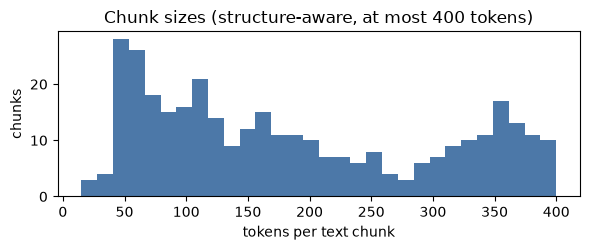

In [10]:
index = pd.read_json(PROCESSED / "chunks.jsonl", lines=True, dtype=False)
display(
    index.groupby(["doc_type", "access_level"]).agg(chunks=("chunk_id", "count"), median_tokens=("tokens", "median"))
)
print("synthetic chunks:", int(index.synthetic.astype(str).eq("True").sum()), "| columns:", ", ".join(index.columns))
card = index[index.doc_type == "stat_card"].iloc[0]
print("\nexample stat card:", card.text)

text_tokens = index[index.doc_type != "stat_card"].tokens
plt.figure(figsize=(6, 2.6))
plt.hist(text_tokens, bins=30, color="#4C78A8")
plt.xlabel("tokens per text chunk")
plt.ylabel("chunks")
plt.title("Chunk sizes (structure-aware, at most 400 tokens)")
plt.tight_layout()
plt.show()

In [11]:
import duckdb

con = duckdb.connect(str(PROCESSED / "stats.duckdb"), read_only=True)
display(
    con.sql(
        "SELECT indicator, residency, seasonal_adjustment, period, value, unit FROM stats_window WHERE indicator = 'unemployment_rate' AND period = '2026-Q2' ORDER BY residency, seasonal_adjustment"
    ).df()
)
con.close()

,indicator,residency,seasonal_adjustment,period,value,unit
0,unemployment_rate,citizen,nsa,2026-Q2,3.6,%
1,unemployment_rate,citizen,sa,2026-Q2,3.0,%
2,unemployment_rate,overall,nsa,2026-Q2,2.3,%
3,unemployment_rate,overall,sa,2026-Q2,1.9,%
4,unemployment_rate,resident,nsa,2026-Q2,3.5,%
5,unemployment_rate,resident,sa,2026-Q2,2.9,%


## Known gaps (details in `docs/DATASHEET.md`)

- Three MOM publications could not be found (3Q 2022 Advance Release, 3Q 2024 Report, 1Q 2026 Report) and are recorded as unresolved.
- MOM pages carry no HTML data tables, so annex tables are unavailable; numbers come from the data.gov.sg series or from prose.
- 12.9% of in-window retrenchment-by-industry cells are suppressed in the source; the system abstains on them.
- MOM page reuse terms are unverified, so raw files are not committed (they are fetched by script and checked against the manifest).
- The seasonal-adjustment basis of annual rates is not stated by the sources and stays `unspecified`.